In [63]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from tensorflow.keras import layers, Model
from skimage.metrics import structural_similarity as ssim

np.random.seed(42)
tf.random.set_seed(42)

In [64]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train[:10000]
y_train = y_train[:10000]

x_test = x_test[:2000]
y_test = y_test[:2000]

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

print("Training:", x_train.shape)
print("Testing:", x_test.shape)

Training: (10000, 28, 28, 1)
Testing: (2000, 28, 28, 1)


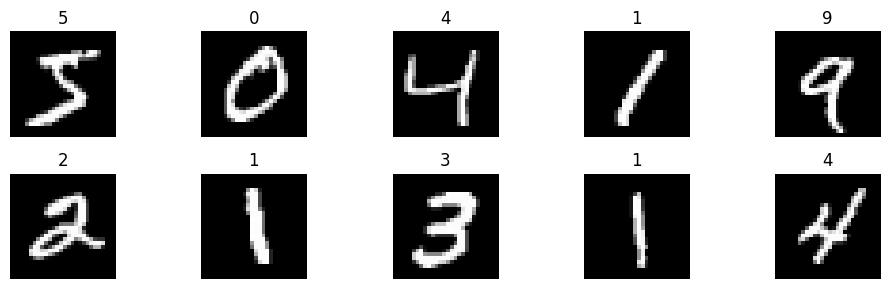

In [65]:
plt.figure(figsize=(10, 3))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.axis("off")
    plt.title(y_train[i])

plt.tight_layout()
plt.show()

##Fully connected autoencoder

In [66]:
latent_dim = 16

encoder_input = layers.Input(shape=(28, 28, 1))

x = layers.Flatten()(encoder_input)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dense(32, activation="relu")(x)
latent = layers.Dense(latent_dim, activation="relu")(x)

encoder = Model(encoder_input, latent, name="FC_Encoder")

decoder_input = layers.Input(shape=(latent_dim,))

x = layers.Dense(32, activation="relu")(decoder_input)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dense(784, activation="sigmoid")(x)
output = layers.Reshape((28, 28, 1))(x)

decoder = Model(decoder_input, output, name="FC_Decoder")

fc_ae = Model(encoder_input, decoder(encoder(encoder_input)))

fc_ae.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy"
)

fc_ae.summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ FC_Encoder (Functional)         │ (None, 16)             │       105,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ FC_Decoder (Functional)         │ (None, 28, 28, 1)      │       105,904 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)

In [67]:
start = time.time()

history_fc = fc_ae.fit(
    x_train, x_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, x_test),
    verbose=1
)

fc_time = time.time() - start

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.3466 - val_loss: 0.2513
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2386 - val_loss: 0.2214
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2084 - val_loss: 0.1943
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1845 - val_loss: 0.1756
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1705 - val_loss: 0.1680
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1639 - val_loss: 0.1622
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1588 - val_loss: 0.1578
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1549 - val_loss: 0.1542
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1512 - val_loss: 0.1505
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1472 - val_loss: 0.1468
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1434 - val_loss: 0.1439
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1405 - val_l

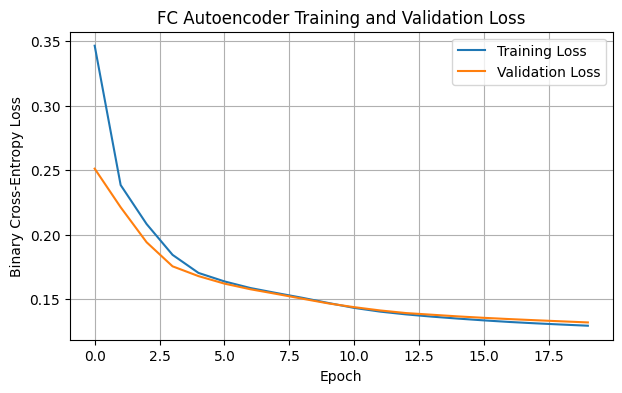

In [68]:
plt.figure(figsize=(7, 4))

plt.plot(history_fc.history["loss"], label="Training Loss")
plt.plot(history_fc.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("FC Autoencoder Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


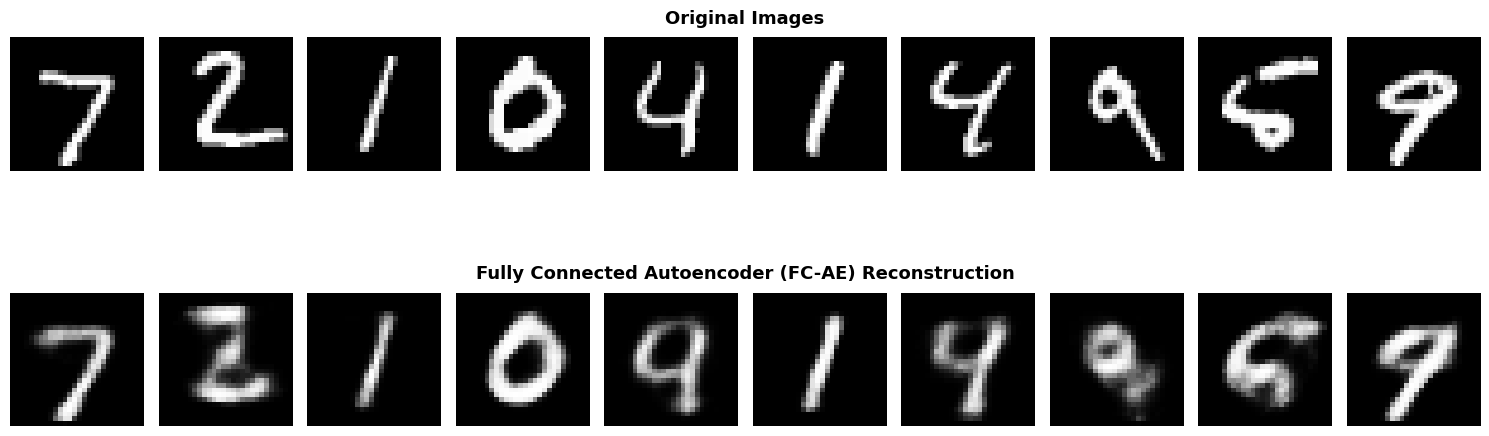

In [69]:
fc_recon = fc_ae.predict(x_test)

fig, axes = plt.subplots(2, 10, figsize=(15, 5))

row_labels = [
    "Original Images",
    "Fully Connected Autoencoder (FC-AE) Reconstruction"
]

for i in range(10):
    axes[0, i].imshow(x_test[i].squeeze(), cmap="gray")
    axes[1, i].imshow(fc_recon[i].squeeze(), cmap="gray")

    for j in range(2):
        axes[j, i].axis("off")

plt.tight_layout()
fig.subplots_adjust(hspace=0.65, top=0.85)

fig.canvas.draw()

for j, label in enumerate(row_labels):
    x_center = (axes[j, 0].get_position().x0 +
                axes[j, -1].get_position().x1) / 2
    y_position = axes[j, 0].get_position().y1 + 0.02

    fig.text(x_center, y_position, label,
             ha="center", va="bottom",
             fontsize=13, fontweight="bold")

plt.show()

In [70]:
def calculate_metrics(original, reconstructed):
    mse = np.mean((original - reconstructed) ** 2)
    mae = np.mean(np.abs(original - reconstructed))

    ssim_values = [
        ssim(original[i].squeeze(),
             reconstructed[i].squeeze(),
             data_range=1.0)
        for i in range(len(original))
    ]

    return mse, mae, np.mean(ssim_values)


fc_mse, fc_mae, fc_ssim = calculate_metrics(x_test, fc_recon)

print("Test MSE:", fc_mse)
print("Test MAE:", fc_mae)
print("Mean SSIM:", fc_ssim)

Test MSE: 0.023736112
Test MAE: 0.06170324
Mean SSIM: 0.7194008203817355


##Convolutional Autoencoders

In [71]:
cae_input = layers.Input(shape=(28, 28, 1))

x = layers.Conv2D(32, 3, activation="relu", padding="same")(cae_input)
x = layers.MaxPooling2D(2, padding="same")(x)

x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
x = layers.MaxPooling2D(2, padding="same")(x)

x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)

x = layers.UpSampling2D(2)(x)
x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)

x = layers.UpSampling2D(2)(x)
cae_output = layers.Conv2D(
    1, 3, activation="sigmoid", padding="same"
)(x)

cae = Model(cae_input, cae_output, name="CAE")

cae.compile(optimizer="adam", loss="binary_crossentropy")

cae.summary()

Model: "CAE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_18 (InputLayer)     │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_55 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_56 (Conv2D)              │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_57 (Conv2D)              │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_18 (UpSampling2D) │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_58 (Conv2D)              │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_19 (UpSampling2D) │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_59 (Conv2D)              │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

In [72]:
start = time.time()

history_cae = cae.fit(
    x_train, x_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, x_test),
    verbose=1
)

cae_time = time.time() - start

cae_recon = cae.predict(x_test)

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - loss: 0.2316 - val_loss: 0.1019
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0917 - val_loss: 0.0825
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0814 - val_loss: 0.0779
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0778 - val_loss: 0.0748
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0757 - val_loss: 0.0733
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0743 - val_loss: 0.0731
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0733 - val_loss: 0.0714
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0726 - val_loss: 0.0709
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0719 - val_loss: 0.0702
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0714 - val_loss: 0.0698
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0709 - val_loss: 0.0694
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0705 - val_l

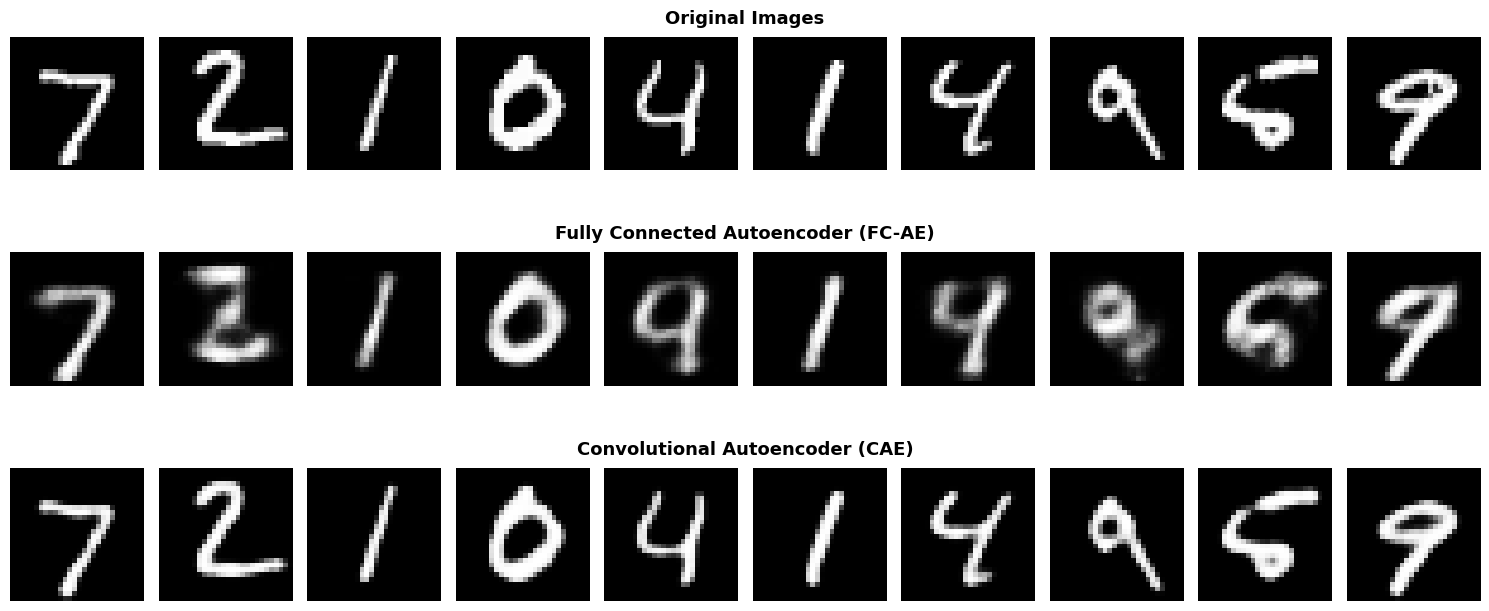

In [73]:
fig, axes = plt.subplots(3, 10, figsize=(15, 6))

row_labels = [
    "Original Images",
    "Fully Connected Autoencoder (FC-AE)",
    "Convolutional Autoencoder (CAE)"
]

for i in range(10):
    axes[0, i].imshow(x_test[i].squeeze(), cmap="gray")
    axes[1, i].imshow(fc_recon[i].squeeze(), cmap="gray")
    axes[2, i].imshow(cae_recon[i].squeeze(), cmap="gray")

    for j in range(3):
        axes[j, i].axis("off")

plt.tight_layout()
fig.subplots_adjust(hspace=0.55)

# Add centered heading above each row
fig.canvas.draw()

for j, label in enumerate(row_labels):
    row_axes = axes[j, :]
    x_center = (row_axes[0].get_position().x0 +
                row_axes[-1].get_position().x1) / 2
    y_position = row_axes[0].get_position().y1 + 0.015

    fig.text(x_center, y_position, label,
             ha="center", va="bottom",
             fontsize=13, fontweight="bold")

plt.show()

In [74]:
cae_mse, cae_mae, cae_ssim = calculate_metrics(x_test, cae_recon)

comparison = pd.DataFrame({
    "Model": ["Fully Connected AE", "Convolutional AE"],
    "MSE": [fc_mse, cae_mse],
    "MAE": [fc_mae, cae_mae],
    "SSIM": [fc_ssim, cae_ssim],
    "Parameters": [fc_ae.count_params(), cae.count_params()],
    "Time (seconds)": [fc_time, cae_time]
})

comparison

,Model,MSE,MAE,SSIM,Parameters,Time (seconds)
0,Fully Connected AE,0.023736,0.061703,0.719401,211040,12.196458
1,Convolutional AE,0.002575,0.015018,0.974521,74497,20.100959


##Denoising autoencoders

In [75]:
# generate Gaussian and Salt-and-Pepper Noise
def gaussian_noise(images, sigma):
    noisy = images + np.random.normal(
        0, sigma, images.shape
    )
    return np.clip(noisy, 0, 1).astype("float32")


def salt_pepper_noise(images, p):
    noisy = images.copy()

    random_values = np.random.rand(*images.shape)

    noisy[random_values < p / 2] = 0
    noisy[(random_values >= p / 2) &
          (random_values < p)] = 1

    return noisy

In [76]:
# buildiung denoising ae
denoise_input = layers.Input(shape=(28, 28, 1))

x = layers.Conv2D(32, 3, activation="relu", padding="same")(denoise_input)
x = layers.MaxPooling2D(2, padding="same")(x)

x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
x = layers.MaxPooling2D(2, padding="same")(x)

x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)

x = layers.UpSampling2D(2)(x)
x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)

x = layers.UpSampling2D(2)(x)
denoise_output = layers.Conv2D(
    1, 3, activation="sigmoid", padding="same"
)(x)

denoiser = Model(denoise_input, denoise_output)

denoiser.compile(optimizer="adam", loss="binary_crossentropy")

In [77]:
#training
x_train_noisy = gaussian_noise(x_train, 0.2)
x_test_noisy = gaussian_noise(x_test, 0.2)

start = time.time()

history_denoise = denoiser.fit(
    x_train_noisy, x_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test_noisy, x_test),
    verbose=1
)

denoise_time = time.time() - start

denoise_recon = denoiser.predict(x_test_noisy)

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - loss: 0.2648 - val_loss: 0.1244
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1077 - val_loss: 0.0967
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0928 - val_loss: 0.0897
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0879 - val_loss: 0.0859
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0853 - val_loss: 0.0825
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0830 - val_loss: 0.0811
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0816 - val_loss: 0.0796
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0806 - val_loss: 0.0787
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0797 - val_loss: 0.0779
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0790 - val_loss: 0.0773
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0784 - val_loss: 0.0769
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0780 - va

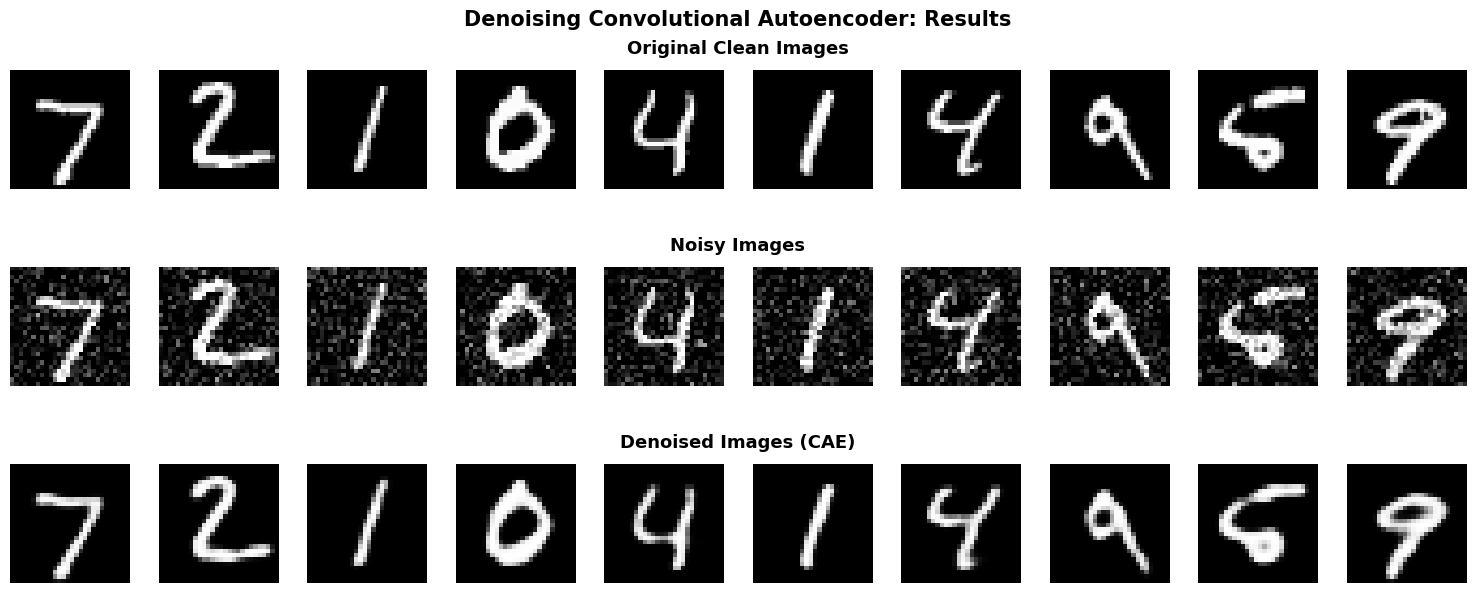

In [78]:
#clean vs noisy vs denoised
fig, axes = plt.subplots(3, 10, figsize=(15, 6))

row_labels = [
    "Original Clean Images",
    "Noisy Images",
    "Denoised Images (CAE)"
]

for i in range(10):
    axes[0, i].imshow(x_test[i].squeeze(), cmap="gray")
    axes[1, i].imshow(x_test_noisy[i].squeeze(), cmap="gray")
    axes[2, i].imshow(denoise_recon[i].squeeze(), cmap="gray")

    for j in range(3):
        axes[j, i].axis("off")

plt.tight_layout()
fig.subplots_adjust(hspace=0.65, top=0.88)

fig.canvas.draw()

for j, label in enumerate(row_labels):
    x_center = (axes[j, 0].get_position().x0 +
                axes[j, -1].get_position().x1) / 2
    y_position = axes[j, 0].get_position().y1 + 0.02

    fig.text(x_center, y_position, label,
             ha="center", va="bottom",
             fontsize=13, fontweight="bold")

fig.suptitle("Denoising Convolutional Autoencoder: Results",
             fontsize=15, fontweight="bold", y=0.98)

plt.show()

In [79]:
noise_results = []

for sigma in [0.1, 0.2, 0.3]:
    noisy = gaussian_noise(x_test, sigma)
    reconstructed = denoiser.predict(noisy, verbose=0)

    mse, mae, ssim_value = calculate_metrics(x_test, reconstructed)

    noise_results.append([sigma, mse, mae, ssim_value])

noise_df = pd.DataFrame(
    noise_results,
    columns=["Noise Level", "MSE", "MAE", "SSIM"]
)

noise_df

,Noise Level,MSE,MAE,SSIM
0,0.1,0.003668,0.017709,0.958170
1,0.2,0.004712,0.021241,0.943865
2,0.3,0.007127,0.028957,0.876097


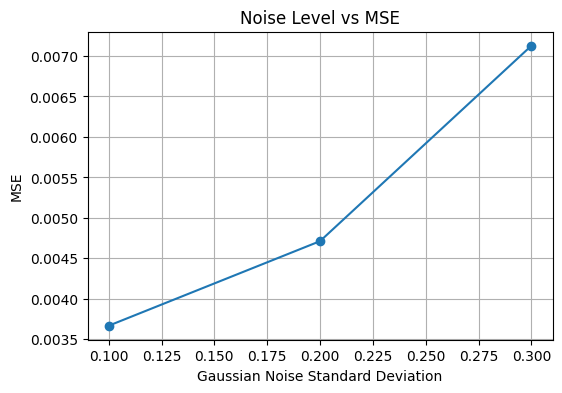

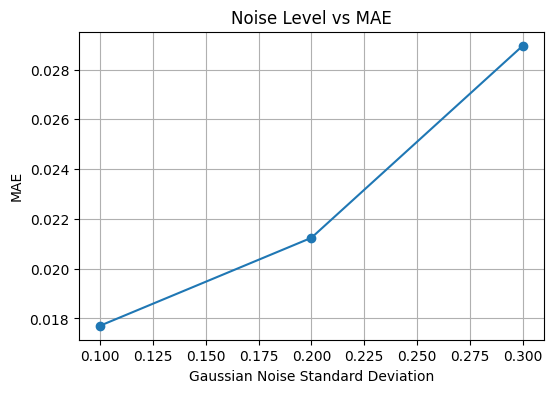

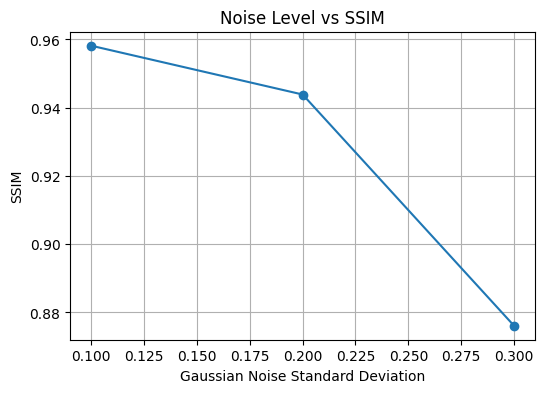

In [80]:
for metric in ["MSE", "MAE", "SSIM"]:
    plt.figure(figsize=(6, 4))
    plt.plot(noise_df["Noise Level"], noise_df[metric], marker="o")
    plt.xlabel("Gaussian Noise Standard Deviation")
    plt.ylabel(metric)
    plt.title(f"Noise Level vs {metric}")
    plt.grid()
    plt.show()

##

##Variational Autoencoder

In [81]:
#building vae
latent_dim_vae = 2

vae_input = layers.Input(shape=(28, 28, 1))

x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(vae_input)
x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)

z_mean = layers.Dense(latent_dim_vae)(x)
z_log_var = layers.Dense(latent_dim_vae)(x)


def sampling(args):
    mean, log_var = args
    epsilon = tf.random.normal(shape=tf.shape(mean))
    return mean + tf.exp(0.5 * log_var) * epsilon


z = layers.Lambda(sampling)([z_mean, z_log_var])

vae_encoder = Model(vae_input, [z_mean, z_log_var, z])


decoder_input = layers.Input(shape=(latent_dim_vae,))

x = layers.Dense(7 * 7 * 64, activation="relu")(decoder_input)
x = layers.Reshape((7, 7, 64))(x)

x = layers.Conv2DTranspose(
    64, 3, strides=2, padding="same", activation="relu"
)(x)

x = layers.Conv2DTranspose(
    32, 3, strides=2, padding="same", activation="relu"
)(x)

decoder_output = layers.Conv2D(
    1, 3, padding="same", activation="sigmoid"
)(x)

vae_decoder = Model(decoder_input, decoder_output)


class VAE(Model):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.total_tracker = tf.keras.metrics.Mean(name="loss")
        self.recon_tracker = tf.keras.metrics.Mean(name="reconstruction_loss")
        self.kl_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_tracker, self.recon_tracker, self.kl_tracker]

    def call(self, inputs):
        _, _, z = self.encoder(inputs)
        return self.decoder(z)

    def train_step(self, data):
        x = data[0] if isinstance(data, tuple) else data

        with tf.GradientTape() as tape:
            mean, log_var, z = self.encoder(x, training=True)
            reconstruction = self.decoder(z, training=True)

            recon_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.losses.binary_crossentropy(x, reconstruction),
                    axis=(1, 2)
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + log_var - tf.square(mean) - tf.exp(log_var),
                    axis=1
                )
            )

            total_loss = recon_loss + kl_loss

        gradients = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_weights))

        self.total_tracker.update_state(total_loss)
        self.recon_tracker.update_state(recon_loss)
        self.kl_tracker.update_state(kl_loss)

        return {
            "loss": self.total_tracker.result(),
            "reconstruction_loss": self.recon_tracker.result(),
            "kl_loss": self.kl_tracker.result()
        }

    def test_step(self, data):
        x = data[0] if isinstance(data, tuple) else data

        mean, log_var, z = self.encoder(x, training=False)
        reconstruction = self.decoder(z, training=False)

        recon_loss = tf.reduce_mean(
            tf.reduce_sum(
                tf.keras.losses.binary_crossentropy(x, reconstruction),
                axis=(1, 2)
            )
        )

        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(
                1 + log_var - tf.square(mean) - tf.exp(log_var),
                axis=1
            )
        )

        total_loss = recon_loss + kl_loss

        self.total_tracker.update_state(total_loss)
        self.recon_tracker.update_state(recon_loss)
        self.kl_tracker.update_state(kl_loss)

        return {
            "loss": self.total_tracker.result(),
            "reconstruction_loss": self.recon_tracker.result(),
            "kl_loss": self.kl_tracker.result()
        }


vae = VAE(vae_encoder, vae_decoder)
vae.compile(optimizer=tf.keras.optimizers.Adam())

In [82]:
#training
start = time.time()

history_vae = vae.fit(
    x_train, x_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, x_test),
    verbose=1
)

vae_time = time.time() - start

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - kl_loss: 2.0964 - loss: 286.1966 - reconstruction_loss: 284.1002 - val_kl_loss: 0.2093 - val_loss: 206.0185 - val_reconstruction_loss: 205.8093
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - kl_loss: 1.3735 - loss: 206.3272 - reconstruction_loss: 204.9538 - val_kl_loss: 3.1994 - val_loss: 190.2611 - val_reconstruction_loss: 187.0617
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - kl_loss: 3.2944 - loss: 189.5049 - reconstruction_loss: 186.2105 - val_kl_loss: 3.8659 - val_loss: 177.5142 - val_reconstruction_loss: 173.6483
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - kl_loss: 3.9809 - loss: 180.6825 - reconstruction_loss: 176.7016 - val_kl_loss: 4.2160 - val_loss: 174.5177 - val_reconstruction_loss: 170.3018
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - kl_loss: 4.1496 - loss: 177.3240 - reconstruction_loss: 173.1745 - val_kl_loss: 4.1829 - val_loss: 170.7140 - val_reconstruction_loss: 166.5311
Epoch 6/20
79/79 

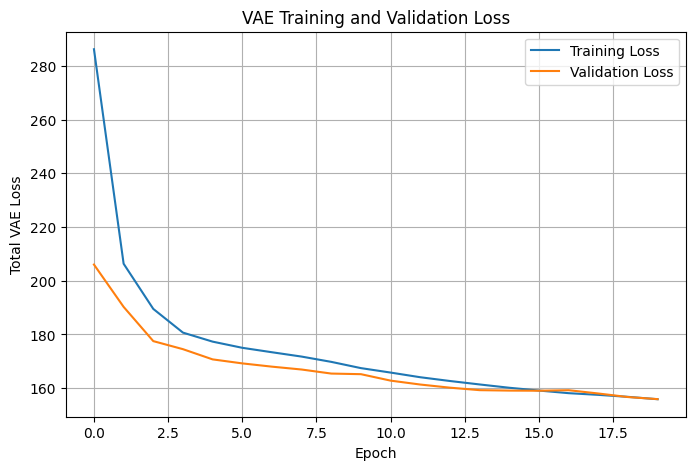

In [83]:
plt.figure(figsize=(8, 5))

plt.plot(history_vae.history["loss"], label="Training Loss")
plt.plot(history_vae.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Total VAE Loss")
plt.title("VAE Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

In [84]:
mean, log_var, z = vae_encoder.predict(x_test)
vae_recon = vae_decoder.predict(z)

vae_mse, vae_mae, vae_ssim = calculate_metrics(x_test, vae_recon)

vae_eval = vae.evaluate(x_test, x_test, return_dict=True)

print("Reconstruction Loss:", vae_eval["reconstruction_loss"])
print("KL Loss:", vae_eval["kl_loss"])
print("Total Loss:", vae_eval["loss"])
print("Test MSE:", vae_mse)
print("Test MAE:", vae_mae)
print("Mean SSIM:", vae_ssim)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - kl_loss: 5.5381 - loss: 155.8989 - reconstruction_loss: 150.3608
Reconstruction Loss: 150.36077880859375
KL Loss: 5.538109302520752
Total Loss: 155.89886474609375
Test MSE: 0.044556446
Test MAE: 0.104463644
Mean SSIM: 0.4779588536489982


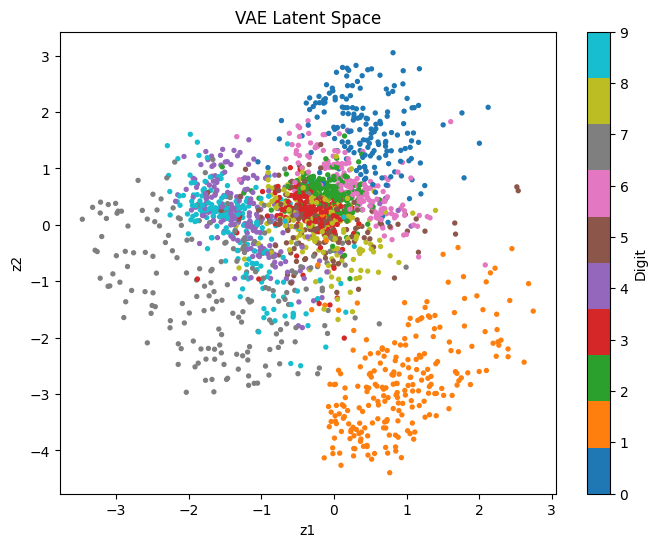

In [85]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    mean[:, 0],
    mean[:, 1],
    c=y_test,
    cmap="tab10",
    s=8
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("VAE Latent Space")
plt.colorbar(scatter, ticks=range(10), label="Digit")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step


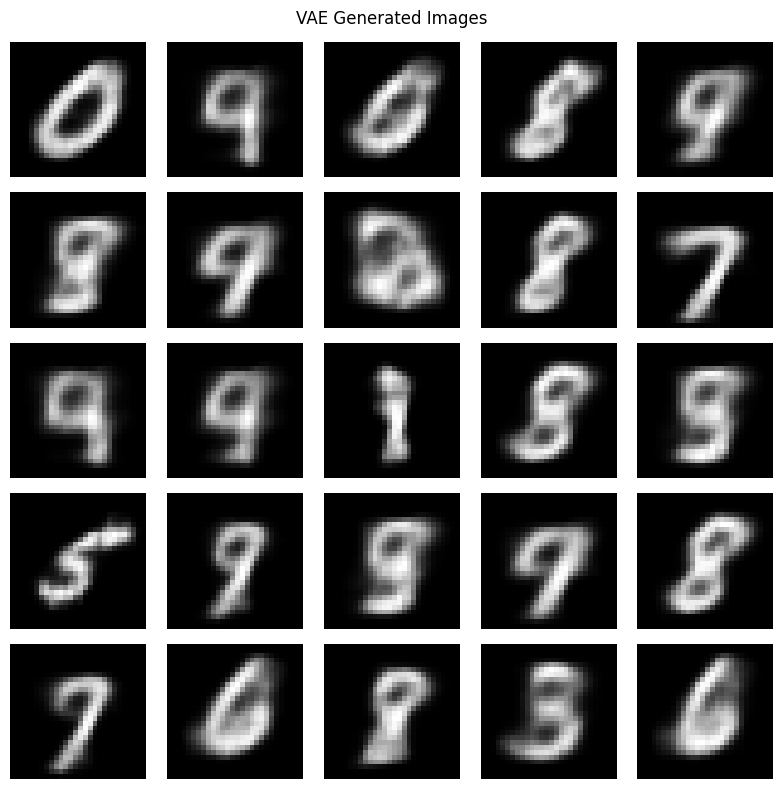

In [86]:
#generating 25 new images
random_z = np.random.normal(size=(25, 2)).astype("float32")

generated = vae_decoder.predict(random_z)

plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(generated[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("VAE Generated Images")
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step


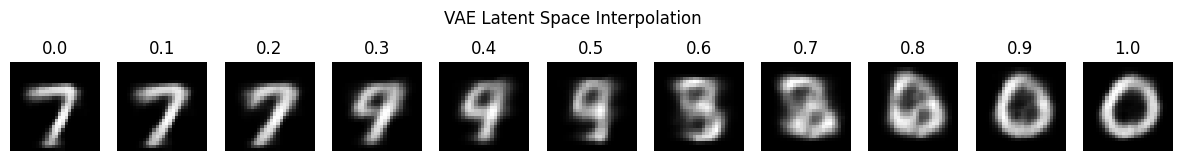

In [87]:
#latent space interpolation
zA = mean[0]
zB = mean[10]

alphas = np.linspace(0, 1, 11)

interpolated_z = np.array([
    (1 - alpha) * zA + alpha * zB
    for alpha in alphas
])

interpolated_images = vae_decoder.predict(interpolated_z)

plt.figure(figsize=(15, 2))

for i in range(11):
    plt.subplot(1, 11, i + 1)
    plt.imshow(interpolated_images[i].squeeze(), cmap="gray")
    plt.axis("off")
    plt.title(f"{alphas[i]:.1f}")

plt.suptitle("VAE Latent Space Interpolation")
plt.show()

##Reconstruction Error Analysis

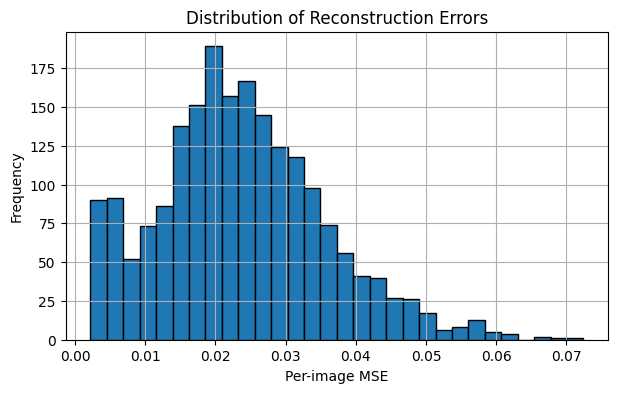

In [88]:
reconstruction_errors = np.mean(
    (x_test - fc_recon) ** 2,
    axis=(1, 2, 3)
)

plt.figure(figsize=(7, 4))
plt.hist(reconstruction_errors, bins=30, edgecolor="black")
plt.xlabel("Per-image MSE")
plt.ylabel("Frequency")
plt.title("Distribution of Reconstruction Errors")
plt.grid()
plt.show()

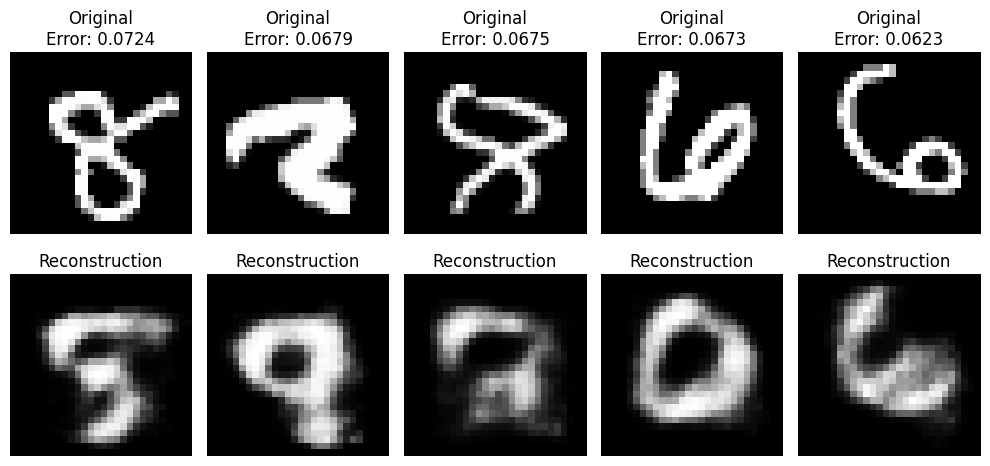

In [89]:
#5 highest error images
high_error_indices = np.argsort(reconstruction_errors)[-5:][::-1]

plt.figure(figsize=(10, 5))

for i, idx in enumerate(high_error_indices):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap="gray")
    plt.title(f"Original\nError: {reconstruction_errors[idx]:.4f}")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(fc_recon[idx].squeeze(), cmap="gray")
    plt.title("Reconstruction")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [90]:
# Build VAE before counting parameters
_ = vae(tf.zeros((1, 28, 28, 1), dtype=tf.float32))

# Calculate denoising metrics
denoise_mse, denoise_mae, denoise_ssim = calculate_metrics(
    x_test, denoise_recon
)

# Final comparison table
final_results = pd.DataFrame({

    "Model": [
        "FC Autoencoder",
        "Convolutional AE",
        "Denoising CAE",
        "VAE"
    ],

    "MSE": [
        fc_mse,
        cae_mse,
        denoise_mse,
        vae_mse
    ],

    "MAE": [
        fc_mae,
        cae_mae,
        denoise_mae,
        vae_mae
    ],

    "SSIM": [
        fc_ssim,
        cae_ssim,
        denoise_ssim,
        vae_ssim
    ],

    "Parameters": [
        fc_ae.count_params(),
        cae.count_params(),
        denoiser.count_params(),
        vae.count_params()
    ],

    "Training Time (seconds)": [
        fc_time,
        cae_time,
        denoise_time,
        vae_time
    ]
})

# Display formatted results
final_results.style.format({
    "MSE": "{:.6f}",
    "MAE": "{:.6f}",
    "SSIM": "{:.4f}",
    "Parameters": "{:,}",
    "Training Time (seconds)": "{:.2f}"
}).hide(axis="index")

Model,MSE,MAE,SSIM,Parameters,Training Time (seconds)
FC Autoencoder,0.023736,0.061703,0.7194,"211,040",12.20
Convolutional AE,0.002575,0.015018,0.9745,"74,497",20.10
Denoising CAE,0.004691,0.021207,0.9440,"74,497",18.85
VAE,0.044556,0.104464,0.4780,"485,957",24.52


##Additional Exercises

In [91]:
#Additional Exercise 1 – CAE with Latent Dimensions 4, 8, 16 and 32
def build_cae_latent(latent_dim):
    inp = layers.Input(shape=(28, 28, 1))

    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inp)
    x = layers.MaxPooling2D(2, padding="same")(x)

    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, padding="same")(x)

    x = layers.Conv2D(latent_dim, 3, activation="relu", padding="same")(x)

    x = layers.UpSampling2D(2)(x)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)

    x = layers.UpSampling2D(2)(x)
    out = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)

    model = Model(inp, out)
    model.compile(optimizer="adam", loss="binary_crossentropy")

    return model


latent_results = []

for dim in [4, 8, 16, 32]:
    model = build_cae_latent(dim)

    model.fit(
        x_train, x_train,
        epochs=10,
        batch_size=128,
        validation_data=(x_test, x_test),
        verbose=0
    )

    recon = model.predict(x_test, verbose=0)
    mse, mae, ssim_value = calculate_metrics(x_test, recon)

    latent_results.append([
        dim, mse, ssim_value, model.count_params()
    ])

latent_df = pd.DataFrame(
    latent_results,
    columns=["Latent Dimension", "MSE", "SSIM", "Parameters"]
)

latent_df

,Latent Dimension,MSE,SSIM,Parameters
0,4,0.005212,0.947464,22597
1,8,0.004720,0.953165,26057
2,16,0.003822,0.961722,32977
3,32,0.003680,0.963081,46817


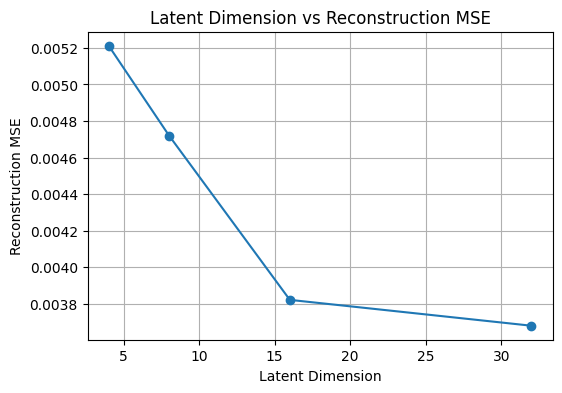

In [92]:
plt.figure(figsize=(6, 4))
plt.plot(latent_df["Latent Dimension"], latent_df["MSE"], marker="o")
plt.xlabel("Latent Dimension")
plt.ylabel("Reconstruction MSE")
plt.title("Latent Dimension vs Reconstruction MSE")
plt.grid()
plt.show()

In [93]:
#Additional Exercise 2 – Gaussian vs Salt-and-Pepper Noise
sp_train = salt_pepper_noise(x_train, 0.1)
sp_test = salt_pepper_noise(x_test, 0.1)

sp_model = build_cae_latent(64)

sp_model.fit(
    sp_train, x_train,
    epochs=20,
    batch_size=128,
    validation_data=(sp_test, x_test),
    verbose=1
)

sp_recon = sp_model.predict(sp_test)

gaussian_metrics = calculate_metrics(x_test, denoise_recon)
sp_metrics = calculate_metrics(x_test, sp_recon)

pd.DataFrame({
    "Noise Type": ["Gaussian (0.2)", "Salt-and-Pepper (0.1)"],
    "MSE": [gaussian_metrics[0], sp_metrics[0]],
    "MAE": [gaussian_metrics[1], sp_metrics[1]],
    "SSIM": [gaussian_metrics[2], sp_metrics[2]]
})

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - loss: 0.2601 - val_loss: 0.1278
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1104 - val_loss: 0.0971
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0949 - val_loss: 0.0912
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0899 - val_loss: 0.0883
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0872 - val_loss: 0.0844
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0848 - val_loss: 0.0834
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0832 - val_loss: 0.0823
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0820 - val_loss: 0.0806
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0811 - val_loss: 0.0799
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0803 - val_loss: 0.0793
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0795 - val_loss: 0.0786
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0789 - val_l

,Noise Type,MSE,MAE,SSIM
0,Gaussian (0.2),0.004691,0.021207,0.943950
1,Salt-and-Pepper (0.1),0.005156,0.021391,0.944048


In [94]:
#Additional Exercise 3 – Compare Two Noise Levels
noise_comparison = []

for sigma in [0.1, 0.3]:
    noisy = gaussian_noise(x_train, sigma)
    noisy_test = gaussian_noise(x_test, sigma)

    model = build_cae_latent(64)

    model.fit(
        noisy, x_train,
        epochs=10,
        batch_size=128,
        validation_data=(noisy_test, x_test),
        verbose=0
    )

    recon = model.predict(noisy_test, verbose=0)

    mse, mae, ssim_value = calculate_metrics(x_test, recon)

    noise_comparison.append([sigma, mse, mae, ssim_value])

pd.DataFrame(
    noise_comparison,
    columns=["Noise Level", "MSE", "MAE", "SSIM"]
)

,Noise Level,MSE,MAE,SSIM
0,0.1,0.004068,0.019453,0.955634
1,0.3,0.008282,0.029554,0.901286


In [95]:
#Additional Exercise 4 – Replace Decoder with Transposed Convolutions
def build_transpose_cae():
    inp = layers.Input(shape=(28, 28, 1))

    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inp)
    x = layers.MaxPooling2D(2, padding="same")(x)

    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, padding="same")(x)

    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)

    x = layers.Conv2DTranspose(
        64, 3, strides=2, padding="same", activation="relu"
    )(x)

    x = layers.Conv2DTranspose(
        32, 3, strides=2, padding="same", activation="relu"
    )(x)

    out = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)

    model = Model(inp, out)
    model.compile(optimizer="adam", loss="binary_crossentropy")

    return model


transpose_cae = build_transpose_cae()

transpose_cae.fit(
    x_train, x_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, x_test),
    verbose=1
)

transpose_recon = transpose_cae.predict(x_test)

print("Upsampling CAE:", calculate_metrics(x_test, cae_recon))
print("Transposed Conv CAE:", calculate_metrics(x_test, transpose_recon))

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - loss: 0.3135 - val_loss: 0.1137
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0955 - val_loss: 0.0826
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0808 - val_loss: 0.0763
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0762 - val_loss: 0.0729
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0736 - val_loss: 0.0710
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0720 - val_loss: 0.0699
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0709 - val_loss: 0.0690
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0701 - val_loss: 0.0683
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0695 - val_loss: 0.0678
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0691 - val_loss: 0.0674
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0686 - val_loss: 0.0670
Epoch 12/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0

In [96]:
##
def build_vae(latent_dim):

    # Encoder
    inputs = layers.Input(shape=(28, 28, 1))

    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(inputs)
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)

    z_mean = layers.Dense(latent_dim)(x)
    z_log_var = layers.Dense(latent_dim)(x)

    def sampling(args):
        mean, log_var = args
        epsilon = tf.random.normal(shape=tf.shape(mean))
        return mean + tf.exp(0.5 * log_var) * epsilon

    z = layers.Lambda(sampling)([z_mean, z_log_var])

    encoder = Model(inputs, [z_mean, z_log_var, z])

    # Decoder
    decoder_input = layers.Input(shape=(latent_dim,))

    x = layers.Dense(7 * 7 * 64, activation="relu")(decoder_input)
    x = layers.Reshape((7, 7, 64))(x)

    x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)

    outputs = layers.Conv2D(1, 3, padding="same", activation="sigmoid")(x)

    decoder = Model(decoder_input, outputs)

    model = VAE(encoder, decoder)

    model.compile(optimizer=tf.keras.optimizers.Adam(0.001))

    return model, encoder, decoder

In [97]:
vae8, encoder8, decoder8 = build_vae(8)

vae8.summary()

Model: "vae_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ functional_26 (Functional)      │ ((None, 8), (None, 8), │       422,416 │
│                                 │ (None, 8))             │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_27 (Functional)      │ (None, 28, 28, 1)      │        83,905 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 506,321 (1.93 MB)

 Trainable params: 506,321 (1.93 MB)

 Non-trainable params: 0 (0.00 B)

In [98]:
start = time.time()

history8 = vae8.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, x_test),
    verbose=1
)

vae8_time = time.time() - start

print("VAE-8 Training Time:", round(vae8_time, 2), "seconds")

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - kl_loss: 5.2236 - loss: 278.3832 - reconstruction_loss: 273.1596 - val_kl_loss: 3.9992 - val_loss: 203.9437 - val_reconstruction_loss: 199.9444
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - kl_loss: 4.4436 - loss: 203.2474 - reconstruction_loss: 198.8039 - val_kl_loss: 4.4773 - val_loss: 189.3419 - val_reconstruction_loss: 184.8646
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - kl_loss: 6.9937 - loss: 182.1120 - reconstruction_loss: 175.1183 - val_kl_loss: 8.5793 - val_loss: 165.5010 - val_reconstruction_loss: 156.9216
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - kl_loss: 10.0132 - loss: 161.1526 - reconstruction_loss: 151.1393 - val_kl_loss: 11.2275 - val_loss: 147.3453 - val_reconstruction_loss: 136.1177
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - kl_loss: 12.6372 - loss: 140.0588 - reconstruction_loss: 127.4216 - val_kl_loss: 13.2974 - val_loss: 133.6983 - val_reconstruction_loss: 120.4008
Epoch 6/20
79

In [99]:
# VAE-2: Existing main experiment
mean2, log_var2, z2 = vae_encoder.predict(x_test, verbose=0)

vae2_recon = vae_decoder.predict(mean2, verbose=0)

# VAE-8: Additional experiment
mean8, log_var8, z8 = encoder8.predict(x_test, verbose=0)

vae8_recon = decoder8.predict(mean8, verbose=0)

print("VAE-2 Reconstruction Shape:", vae2_recon.shape)
print("VAE-8 Reconstruction Shape:", vae8_recon.shape)

VAE-2 Reconstruction Shape: (2000, 28, 28, 1)
VAE-8 Reconstruction Shape: (2000, 28, 28, 1)


In [100]:
# VAE-2 metrics
vae2_mse, vae2_mae, vae2_ssim = calculate_metrics(
    x_test, vae2_recon
)

# VAE-8 metrics
vae8_mse, vae8_mae, vae8_ssim = calculate_metrics(
    x_test, vae8_recon
)

print("VAE-2 Results")
print("MSE :", vae2_mse)
print("MAE :", vae2_mae)
print("SSIM:", vae2_ssim)

print("\nVAE-8 Results")
print("MSE :", vae8_mse)
print("MAE :", vae8_mae)
print("SSIM:", vae8_ssim)

VAE-2 Results
MSE : 0.04410918
MAE : 0.10385648
SSIM: 0.48199086395620566

VAE-8 Results
MSE : 0.01983047
MAE : 0.052548185
SSIM: 0.7847879190904281


In [101]:
# Build models before counting parameters
_ = vae(tf.zeros((1, 28, 28, 1)))
_ = vae8(tf.zeros((1, 28, 28, 1)))

# Evaluate VAE-2
vae2_eval = vae.evaluate(
    x_test, x_test,
    batch_size=128,
    verbose=0,
    return_dict=True
)

# Evaluate VAE-8
vae8_eval = vae8.evaluate(
    x_test, x_test,
    batch_size=128,
    verbose=0,
    return_dict=True
)

print("VAE-2")
print("Reconstruction Loss:", vae2_eval["reconstruction_loss"])
print("KL Loss:", vae2_eval["kl_loss"])
print("Total Loss:", vae2_eval["loss"])
print("Parameters:", vae.count_params())

print("\nVAE-8")
print("Reconstruction Loss:", vae8_eval["reconstruction_loss"])
print("KL Loss:", vae8_eval["kl_loss"])
print("Total Loss:", vae8_eval["loss"])
print("Parameters:", vae8.count_params())

VAE-2
Reconstruction Loss: 150.32919311523438
KL Loss: 5.532684803009033
Total Loss: 155.86187744140625
Parameters: 485957

VAE-8
Reconstruction Loss: 98.3565444946289
KL Loss: 16.728437423706055
Total Loss: 115.08497619628906
Parameters: 506321


In [102]:
vae_comparison = pd.DataFrame({

    "Latent Dimension": [2, 8],

    "MSE": [
        vae2_mse,
        vae8_mse
    ],

    "MAE": [
        vae2_mae,
        vae8_mae
    ],

    "SSIM": [
        vae2_ssim,
        vae8_ssim
    ],

    "Reconstruction Loss": [
        vae2_eval["reconstruction_loss"],
        vae8_eval["reconstruction_loss"]
    ],

    "KL Loss": [
        vae2_eval["kl_loss"],
        vae8_eval["kl_loss"]
    ],

    "Total Loss": [
        vae2_eval["loss"],
        vae8_eval["loss"]
    ],

    "Parameters": [
        vae.count_params(),
        vae8.count_params()
    ],

    "Training Time (seconds)": [
        vae_time,
        vae8_time
    ]
})

vae_comparison.style.format({
    "MSE": "{:.6f}",
    "MAE": "{:.6f}",
    "SSIM": "{:.4f}",
    "Reconstruction Loss": "{:.4f}",
    "KL Loss": "{:.4f}",
    "Total Loss": "{:.4f}",
    "Parameters": "{:,}",
    "Training Time (seconds)": "{:.2f}"
}).hide(axis="index")

Latent Dimension,MSE,MAE,SSIM,Reconstruction Loss,KL Loss,Total Loss,Parameters,Training Time (seconds)
2,0.044109,0.103856,0.4820,150.3292,5.5327,155.8619,"485,957",24.52
8,0.019830,0.052548,0.7848,98.3565,16.7284,115.0850,"506,321",22.93


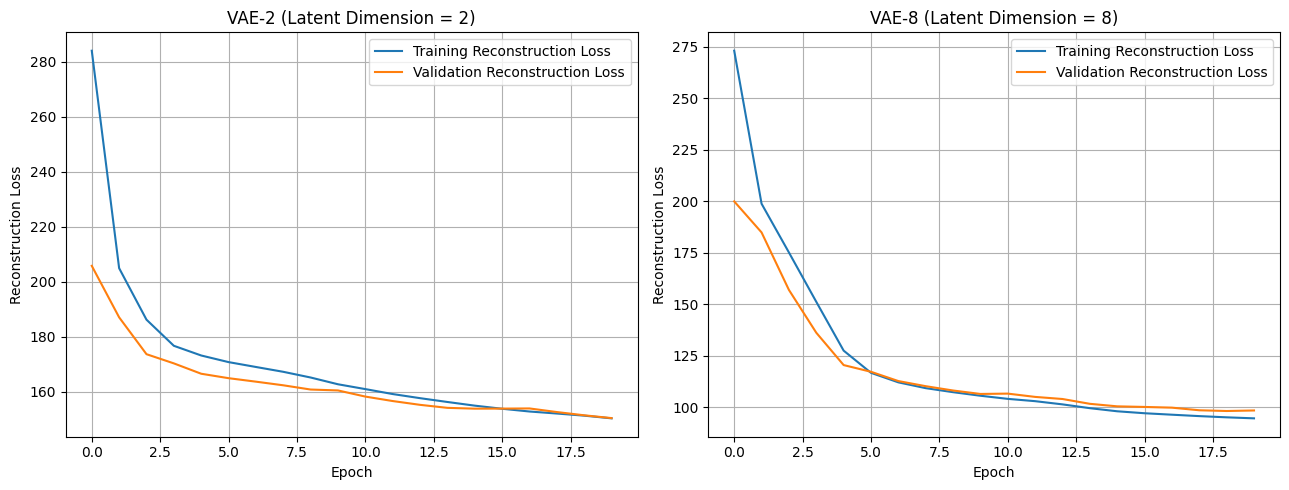

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# VAE-2
axes[0].plot(
    history_vae.history["reconstruction_loss"],
    label="Training Reconstruction Loss"
)

axes[0].plot(
    history_vae.history["val_reconstruction_loss"],
    label="Validation Reconstruction Loss"
)

axes[0].set_title("VAE-2 (Latent Dimension = 2)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Reconstruction Loss")
axes[0].legend()
axes[0].grid()

# VAE-8
axes[1].plot(
    history8.history["reconstruction_loss"],
    label="Training Reconstruction Loss"
)

axes[1].plot(
    history8.history["val_reconstruction_loss"],
    label="Validation Reconstruction Loss"
)

axes[1].set_title("VAE-8 (Latent Dimension = 8)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Reconstruction Loss")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

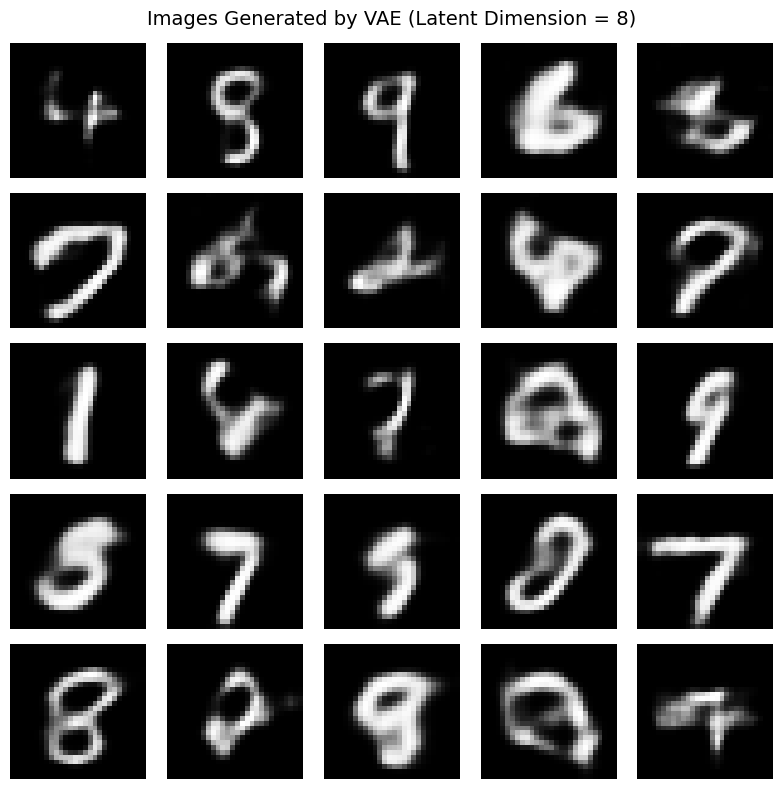

In [104]:
random_z8 = np.random.normal(
    size=(25, 8)
).astype("float32")

generated8 = decoder8.predict(random_z8, verbose=0)

fig, axes = plt.subplots(5, 5, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated8[i].squeeze(), cmap="gray")
    ax.axis("off")

fig.suptitle(
    "Images Generated by VAE (Latent Dimension = 8)",
    fontsize=14
)

plt.tight_layout()
plt.show()

##additional 6

In [109]:
class BetaVAE(VAE):
    def __init__(self, encoder, decoder, beta):
        super().__init__(encoder, decoder)

        self.beta = beta

        # Explicitly initialize metric trackers
        self.loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker
        ]

    def compute_losses(self, data, training):
        if isinstance(data, tuple):
            data = data[0]

        mean, log_var, z = self.encoder(data, training=training)
        reconstruction = self.decoder(z, training=training)

        recon_loss = tf.reduce_mean(
            tf.reduce_sum(
                tf.keras.losses.binary_crossentropy(data, reconstruction),
                axis=(1, 2)
            )
        )

        kl_loss = tf.reduce_mean(
            -0.5 * tf.reduce_sum(
                1 + log_var - tf.square(mean) - tf.exp(log_var),
                axis=1
            )
        )

        total_loss = recon_loss + self.beta * kl_loss

        return total_loss, recon_loss, kl_loss

    def train_step(self, data):
        with tf.GradientTape() as tape:
            total_loss, recon_loss, kl_loss = self.compute_losses(
                data, training=True
            )

        gradients = tape.gradient(total_loss, self.trainable_weights)

        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_weights)
        )

        self.loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        total_loss, recon_loss, kl_loss = self.compute_losses(
            data, training=False
        )

        self.loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {m.name: m.result() for m in self.metrics}

In [110]:
beta_values = [0.5, 2.0]

beta_models = {}
beta_encoders = {}
beta_decoders = {}
beta_histories = {}

for beta in beta_values:

    _, encoder_beta, decoder_beta = build_vae(2)

    model = BetaVAE(encoder_beta, decoder_beta, beta)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        run_eagerly=True
    )

    print(f"\nTraining Beta-VAE with beta = {beta}")

    history = model.fit(
        x_train,
        epochs=20,
        batch_size=128,
        validation_data=(x_test, x_test),
        verbose=1
    )

    beta_models[beta] = model
    beta_encoders[beta] = encoder_beta
    beta_decoders[beta] = decoder_beta
    beta_histories[beta] = history


Training Beta-VAE with beta = 0.5
Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 13s 157ms/step - kl_loss: 6.8290 - loss: 278.8655 - reconstruction_loss: 275.4510 - val_kl_loss: 4.5267 - val_loss: 195.8940 - val_reconstruction_loss: 193.6307
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 129ms/step - kl_loss: 4.1207 - loss: 196.5745 - reconstruction_loss: 194.5142 - val_kl_loss: 4.0498 - val_loss: 187.2054 - val_reconstruction_loss: 185.1805
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 125ms/step - kl_loss: 4.5248 - loss: 186.8032 - reconstruction_loss: 184.5408 - val_kl_loss: 5.1463 - val_loss: 176.8380 - val_reconstruction_loss: 174.2648
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 11s 135ms/step - kl_loss: 5.2975 - loss: 177.5133 - reconstruction_loss: 174.8645 - val_kl_loss: 5.5977 - val_loss: 171.7239 - val_reconstruction_loss: 168.9250
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 11s 136ms/step - kl_loss: 5.4703 - loss: 173.1863 - reconstruction_loss: 170.4512 - val_kl_loss: 5.6783 - val_loss: 169.5937 - val_

In [111]:
beta_results = []

for beta in beta_values:

    results = beta_models[beta].evaluate(
        x_test,
        x_test,
        return_dict=True,
        verbose=0
    )

    beta_results.append({
        "Beta": beta,
        "Reconstruction Loss": results["reconstruction_loss"],
        "KL Loss": results["kl_loss"],
        "Total Loss": results["loss"]
    })

beta_df = pd.DataFrame(beta_results)

display(beta_df.round(4))

,Beta,Reconstruction Loss,KL Loss,Total Loss
0,0.5,149.6683,7.2800,153.3083
1,2.0,150.0229,4.8984,159.8197


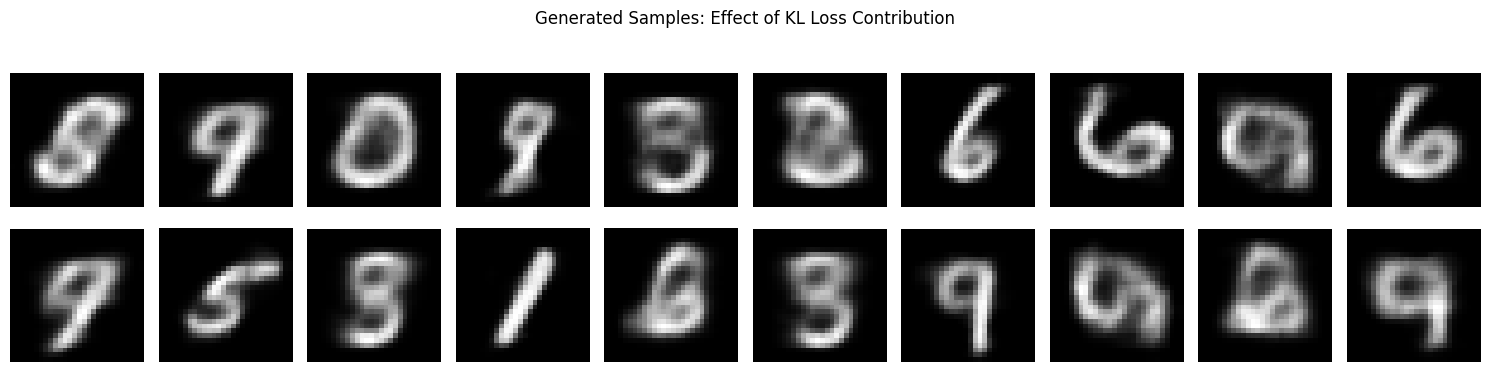

In [112]:
np.random.seed(42)

z_samples = np.random.normal(size=(10, 2)).astype("float32")

fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for row, beta in enumerate(beta_values):

    generated = beta_decoders[beta].predict(z_samples, verbose=0)

    for col in range(10):
        axes[row, col].imshow(generated[col].squeeze(), cmap="gray")
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(f"Beta = {beta}", fontsize=12)

plt.suptitle("Generated Samples: Effect of KL Loss Contribution")
plt.tight_layout()
plt.show()

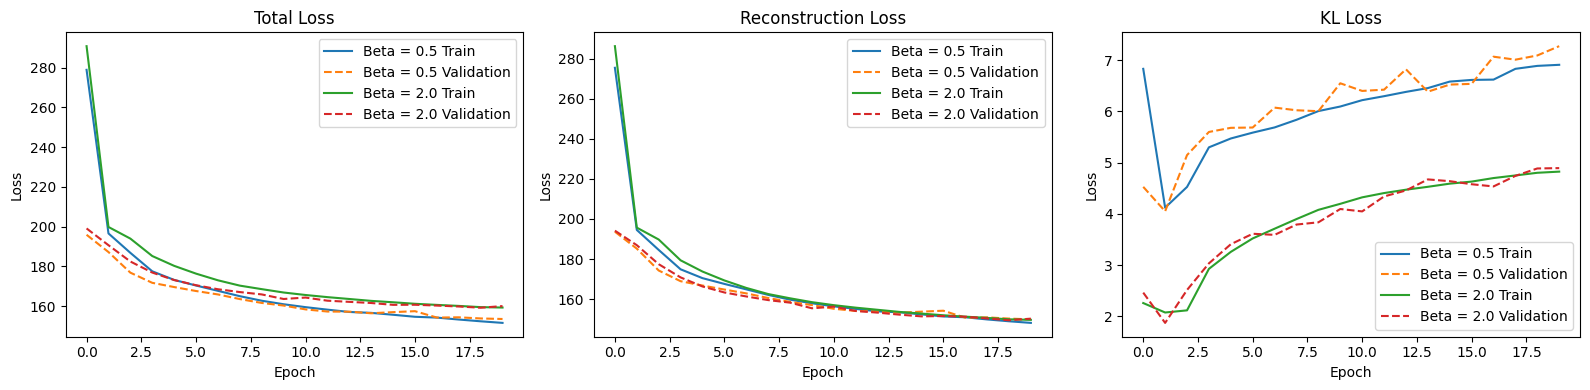

In [113]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

loss_types = [
    ("loss", "Total Loss"),
    ("reconstruction_loss", "Reconstruction Loss"),
    ("kl_loss", "KL Loss")
]

for ax, (key, title) in zip(axes, loss_types):

    for beta in beta_values:
        history = beta_histories[beta].history

        ax.plot(
            history[key],
            label=f"Beta = {beta} Train"
        )

        ax.plot(
            history[f"val_{key}"],
            linestyle="--",
            label=f"Beta = {beta} Validation"
        )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.show()

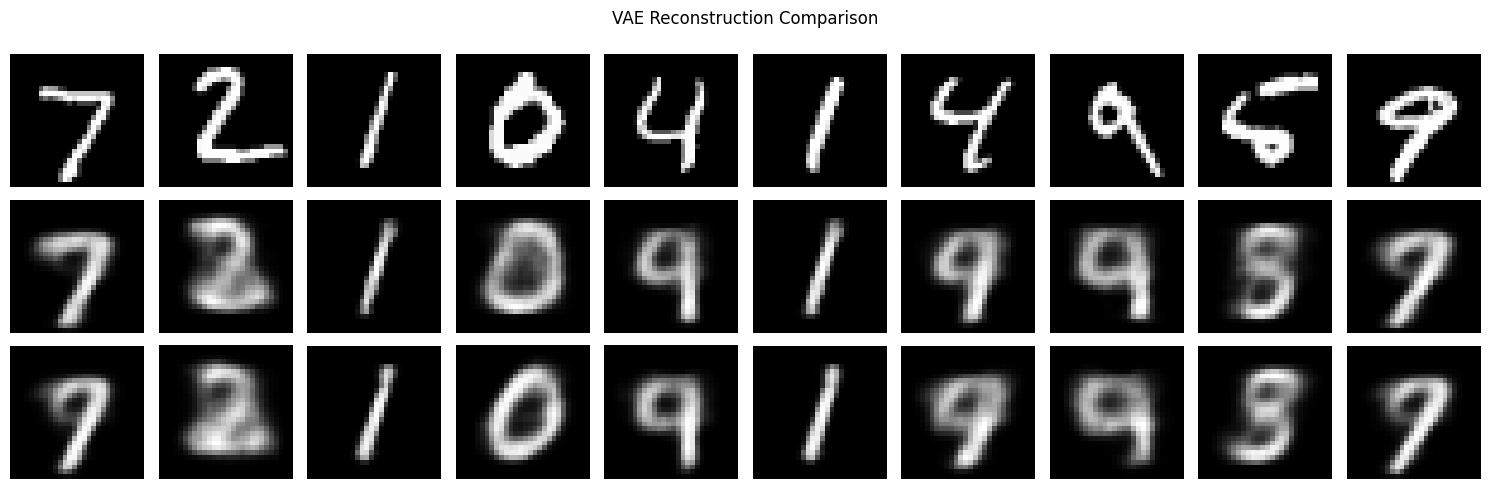

In [114]:
n = 10

mean_05, _, _ = beta_encoders[0.5].predict(x_test[:n], verbose=0)
mean_2, _, _ = beta_encoders[2.0].predict(x_test[:n], verbose=0)

recon_05 = beta_decoders[0.5].predict(mean_05, verbose=0)
recon_2 = beta_decoders[2.0].predict(mean_2, verbose=0)

fig, axes = plt.subplots(3, n, figsize=(15, 5))

for i in range(n):
    axes[0, i].imshow(x_test[i].squeeze(), cmap="gray")
    axes[1, i].imshow(recon_05[i].squeeze(), cmap="gray")
    axes[2, i].imshow(recon_2[i].squeeze(), cmap="gray")

    for j in range(3):
        axes[j, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Beta = 0.5")
axes[2, 0].set_ylabel("Beta = 2.0")

plt.suptitle("VAE Reconstruction Comparison")
plt.tight_layout()
plt.show()

##additional 7


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


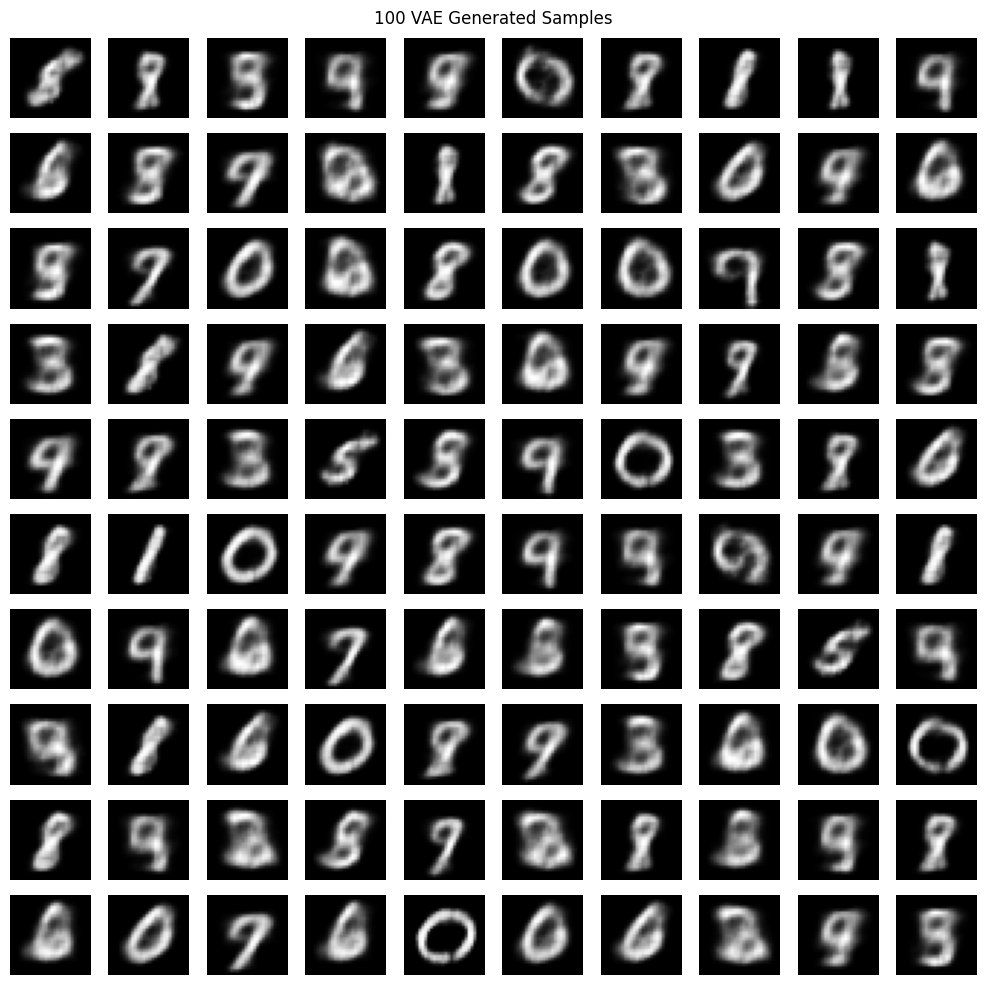

In [115]:
random_z = np.random.normal(size=(100, 2)).astype("float32")

generated = vae_decoder.predict(random_z)

plt.figure(figsize=(10, 10))

for i in range(100):
    plt.subplot(10, 10, i + 1)
    plt.imshow(generated[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("100 VAE Generated Samples")
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


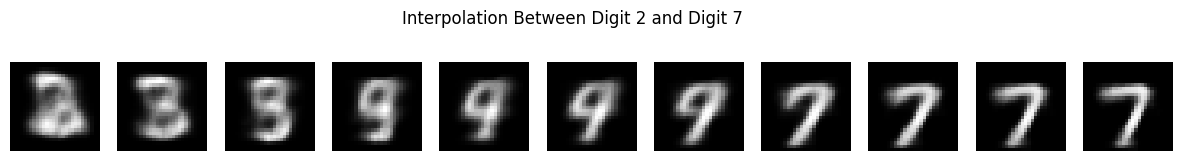

In [116]:
#additional 8
digit_a = np.where(y_test == 2)[0][0]
digit_b = np.where(y_test == 7)[0][0]

zA = mean[digit_a]
zB = mean[digit_b]

alphas = np.linspace(0, 1, 11)

interpolated_z = np.array([
    (1 - a) * zA + a * zB for a in alphas
])

interpolated_images = vae_decoder.predict(interpolated_z)

plt.figure(figsize=(15, 2))

for i in range(11):
    plt.subplot(1, 11, i + 1)
    plt.imshow(interpolated_images[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("Interpolation Between Digit 2 and Digit 7")
plt.show()